In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load Data:

For this tutorial we will use simulated spiking data from the c3po publication.

In [7]:
from huggingface_hub import snapshot_download
cache_dir = Path("~/c3po_cache").expanduser() # local cache directory for dataset

local_repo = snapshot_download(
    repo_id="samuelbray32/c3po-publication",
    repo_type="dataset",
    allow_patterns="Fig1_simulation/*.pkl",
    local_dir=cache_dir,
)
local_dir = Path(local_repo) / "Fig1_simulation"
spiking_df = pd.read_pickle(local_dir / "spiking_data.pkl")
neuron_df = pd.read_pickle(local_dir / "neuron_data.pkl")
metadata_df = pd.read_pickle(local_dir / "metadata.pkl")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

# Format data

Training clusterless data requires 3 arrays:
- `mark_waveforms`: a `(n_spikes, n_features)` array of the featurized waveforms
- `mark_times`: a `(n_spikes,)` array of spike times (in seconds)
- `shank_ids` (optional): a `(n_spikes)` array of the integer id that a waveform
  was detected on.  If not provided, assumes all events from one shank

In [21]:
mark_waveforms = np.column_stack(spiking_df.mark.values).T
shank_ids = np.array(spiking_df.unit.values) % 2 # pretend that the units are on two shanks for this example
mark_times = np.array(spiking_df.time.values)

print("Data Shapes:")
print(f"Mark Waveforms: (n_spikes, n_channels)")
print(f"Shank IDs: (n_spikes,)")
print(f"Mark Times: (n_spikes,)")

Data Shapes:
Mark Waveforms: (n_spikes, n_channels)
Shank IDs: (n_spikes,)
Mark Times: (n_spikes,)


# Feature regularization

If you haven't already we recommend some form of feature standardization to ensure 
they are numerically well-conditioned for training.  One example approach is
shown below

Text(0.5, 1.0, 'Example mark waveforms')

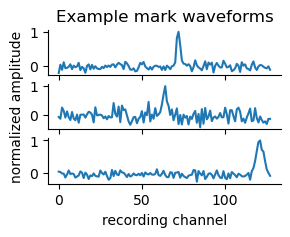

In [ ]:
# Recommend normalizing the waveforms prior to training to ensure they are well-conditioned for the model.
mark_waveforms = mark_waveforms / np.max(np.abs(mark_waveforms), axis=1, keepdims=True)
mark_waveforms = mark_waveforms - np.mean(mark_waveforms, axis=1, keepdims=True)

# plot a few example waveforms
fig, ax = plt.subplots(3, 1, figsize=(3,2),sharex=True)
for i in range(3):
    ax[i].plot(mark_waveforms[i])
    ax[i].spines[["top", "right"]].set_visible(False)
ax[-1].set_xlabel("recording channel")
ax[1].set_ylabel("normalized amplitude")
ax[0].set_title("Example mark waveforms")

# Train Model

Here we train a 16-dimensional c3po model with default architecture.
Model results are saved to `output_dir` and can be reloaded from there.

You can also define your own model architecture by providing a dictionary of
c3po model arguments to `model_args` (or a path to a config of the same)

For a deeper understanding of these options see [this deep dive tutorial](./sorted_units_deep_dive.ipynb)

In [ ]:
dimensions = 16 # dimension of the c3po embedding

# Define the output directory for the trained model and analysis outputs
output_dir = Path("/home/sambray/Downloads/demo_clusterless_model")
output_dir.mkdir(parents=True, exist_ok=True)

# Train a clusterless C3PO model directly from the waveform data
from c3po.utils.clusterless import train_from_waveform_data
analysis = train_from_waveform_data(
    mark_waveforms=mark_waveforms,
    shank_ids=shank_ids,
    mark_times=mark_times,
    dimensions=dimensions,
    output_dir=output_dir,
)


Average multi-unit activity rate: 49.30 Hz
Average sample duration: 40.57 seconds
x shape (10, 129)


Epoch 1:   0%|          | 0/245 [00:00<?, ?samples/s]

x shape (64, 129)


Epoch 9:   0%|          | 0/245 [00:00<?, ?samples/s]

x shape (64, 129)


Epoch 46:   0%|          | 0/245 [00:00<?, ?samples/s]

... (18 outputs left out)

x shape (1, 129)


 83%|████████▎ | 205000/246497 [00:02<00:00, 153691.36it/s]

x shape (1, 129)


 97%|█████████▋| 240000/246497 [00:03<00:00, 63829.49it/s] 


# Plot output

Text(0.5, 0, 'Time (s)')

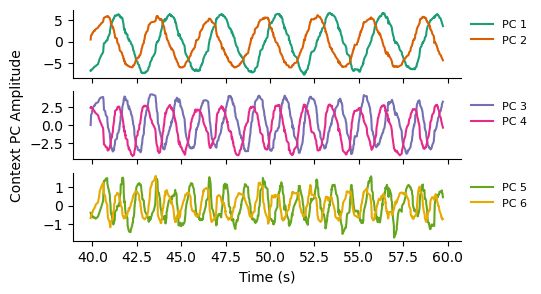

In [ ]:
ind = slice (1000,3000)

fig, ax = plt.subplots(nrows=3, sharex=True, figsize=(5, 3))
for i in range(3):
    for j in range(2):
        pc = 2*i+j
        color = plt.cm.Dark2(pc/8)
        ax[i].plot(analysis.t[ind], analysis.c_pca[ind,pc], label=f"PC {pc+1}", color=color)
    ax[i].legend(frameon=False, fontsize=8, loc="upper left",bbox_to_anchor=(1, 1))
    ax[i].spines[["top", "right"]].set_visible(False)

ax[1].set_ylabel("Context PC Amplitude")
ax[-1].set_xlabel("Time (s)")

# Re-load trained model

We can re-load a trained c3po model from the output directory for re-use and
future analysis

In [ ]:
from c3po.analysis.analysis import C3poAnalysis

output_dir = Path("/home/sambray/Downloads/demo_clusterless_model")
analysis = C3poAnalysis(model_dir=output_dir,)

analysis.fit_context_pca() # recompute the context PCA if it was not saved during training

we can then plot from the loaded results

Text(0.5, 0, 'Time (s)')

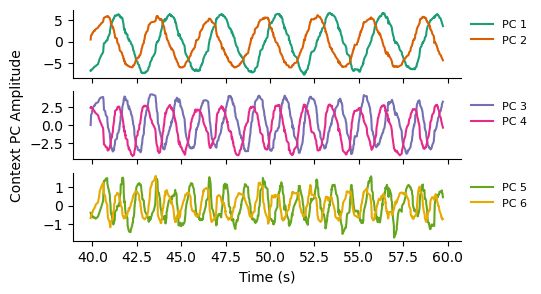

In [ ]:
ind = slice (1000,3000)
fig, ax = plt.subplots(nrows=3, sharex=True, figsize=(5, 3))
for i in range(3):
    for j in range(2):
        pc = 2*i+j
        color = plt.cm.Dark2(pc/8)
        ax[i].plot(analysis.t[ind], analysis.c_pca[ind,pc], label=f"PC {pc+1}", color=color)
    ax[i].legend(frameon=False, fontsize=8, loc="upper left",bbox_to_anchor=(1, 1))
    ax[i].spines[["top", "right"]].set_visible(False)

ax[1].set_ylabel("Context PC Amplitude")
ax[-1].set_xlabel("Time (s)")